# Exploration de techniques pour produire des perturbations pour les méthodes d'explication par *Activation Patching*

## Background
### Activation Patching [[Geiger et al., 2021](https://dl.acm.org/doi/10.5555/3540261.3540994)] 
Les méthodes par activation patching cherchent à identifier les composants (neurones, couches, tête d'attention,...) des modèles d'apprentissage profond sensibles à certains changements dans l'entrée ou à certaines caractéristiques. L'objectif peut être de localiser les compétences linguistiques ou la sensibilité à un certain domaine ou vocabulaire dans un modèle de langue. 

Pour produire ces explications, la méthode présentée par [[Geiger et al., 2021](https://dl.acm.org/doi/10.5555/3540261.3540994)] procède ainsi:  
Soient $M$ le modèle étudié qui contient des composants (neurone ou tête d'attention) $M_{i,j}$, $\mathcal{D}$ un dataset et $P$ une fonction qui à une entrée de $e \in \mathcal{D}$ lui associe une version perturbée $e'$. On pose $\mathcal{D}'$ le dataset issu de $\mathcal{D}$ dont chaque entrée est perturbée selon $P$.  
Itérativement, on effectue pour chaque composant $M_{i,j}$:

- une passe de $\mathcal{D}$ dans $M$ en notant la valeur en sortie de $M_{i,j}$ ($v_e$) pour chaque entrée $e$. On note sa performance $p$.
- une passe de $\mathcal{D}'$ dans $M$. On note sa performance $p_{\mathcal{D}'}$.
- une passe de $\mathcal{D}'$ dans $M$ où la sortie du composant $M_{i,j}$ est fixée à $v_e$ pour l'entrée $e' = P(e)$. On note sa performance $p_{i,j}'$.

Ainsi, on obtient une différence de performance $p - p_{i,j}'$ pour chaque composant $M_{i,j}$ qui peut être interprété comme la sensibilité du composant $M_{i,j}$ à la perturbation $P$.


### Activation patching pour l'extraction de document [[Chen et al., 2024](https://dl.acm.org/doi/10.1145/3626772.3657841)]
[[Chen et al., 2024](https://dl.acm.org/doi/10.1145/3626772.3657841)] propose une adaptation de la méthode d'activation patching pour les modèles d'extraction d'information par plongement des documents et des requêtes à l'aide d'un modèle bi-encodeur.  
On conserve les notations précédentes. $\mathcal{D}$ est l'ensemble des documents et $\mathcal{Q}$ est l'ensemble des requêtes.

Itérativement, on effectue pour chaque composant $M_{i,j}$:

- une passe des paires étiquetées $ \subset \mathcal{Q} \times \mathcal{D}$ dans $M$ en notant la valeur en sortie de $M_{i,j}$ ($v^\mathcal{D}_e$) pour chaque entrée $e=(q,d)$. On note sa performance $p_{\mathcal{D}} = moy_{(q,d) \in \mathcal{Q} \times \mathcal{D}} (M(q)\bullet M(d))$.
- une passe des paires étiquetées $ \subset \mathcal{Q} \times \mathcal{D'}$ dans $M$ en notant la valeur en sortie de $M_{i,j}$ ($v^\mathcal{D'}_e$) pour chaque entrée $e=(q,d')$. On note sa performance $p_{\mathcal{D'}} = moy_{(q,d') \in \mathcal{Q} \times \mathcal{D'}} (M(q)\bullet M(d'))$.
- On pose $ \forall e \in \mathcal{Q} \times \mathcal{D}, v_e = v^{\mathcal{S}}_e$ où $\mathcal{S}$ est tel que $p_{\mathcal{S}} = max\{p_{\mathcal{D}}, p_{\mathcal{D'}}\}$ ($p_{\mathcal{V}} = min\{p_{\mathcal{D}}, p_{\mathcal{D'}}\}$) 
- une passe de $\mathcal{V}$ dans $M$ où la sortie du composant $M_{i,j}$ est fixée à $v^{\mathcal{S}}_e$ pour l'entrée $e' = P(e)$. On note sa performance $p_{i,j}'$.

Ainsi, on peut considérer
$$
p = \frac{p_{\mathcal{S}} - p_{\mathcal{D}}}{p_{\mathcal{D}'} - p_{\mathcal{D}}} 
$$
comme la sensibilité composant $M_{i,j}$ à la perturbation $P$. Les sensibilités de chaque composant peut être récapitulé dans un tableau. 


Remarques:
- La méthode proposée prend en compte les perturbations pouvant augmenter ou diminuer la performance.
- La métrique couramment utilisée pour la performance est la proximité entre les représentations d'une requête et d'un document (ie. le produit scalaire).


### MerchIR
[[Parry et al., 2025](https://arxiv.org/abs/2501.10165)] propose une implémentation de la méthode de [[Chen et al., 2024](https://dl.acm.org/doi/10.1145/3626772.3657841)] : [Github](https://github.com/Parry-Parry/MechIR.git).  
En fournissant un modèle, une base de données et une fonction de perturbation, la librairie MechIR permet de construire le tableau des perturbations que chaque composant de l'architecture fournie.

On développe dans la suite des méthodes et approches pour exploiter au mieux cette librairie.

#### Préparation des uotils de travail de MechIR

In [1]:
# Librairies Necessaires

from mechir import Dot
from mechir.data import MechIRDataset, DotDataCollator
from mechir.perturb import perturbation
from mechir.plotting import plot_components

import torch
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns

/home/marine/Documents/Cours/M2GPEx/ProjetIndividuel/Travaux/stagexairag/venv-mechir/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-04-08 13:11:34.469 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [2]:
# Fonctions auxiliaires (pas besoin de lire)
def pretty_print_triplets(batch, tokenizer, num=1):
    """
    Pretty prints triplets of queries, documents, and their corresponding perturbed documents from a batch.

    Args:
        batch (dict): A dictionary containing 'queries', 'documents', and 'perturbed_documents' from a DataLoader.
        tokenizer: The tokenizer used to decode the input IDs.
        num (int): Number of examples to show per batch.
    """
    # Get the queries, documents, and perturbed documents from the batch
    queries = batch["queries"]
    documents = batch["documents"]
    perturbed_documents = batch["perturbed_documents"]

    # Loop through number of examples to show in batch
    for i in range(len(documents["input_ids"][:num])):
        # Get the input IDs
        query_ids = queries["input_ids"][i]
        original_ids = documents["input_ids"][i]
        perturbed_ids = perturbed_documents["input_ids"][i]

        # Decode the input IDs to text
        query_decoded = tokenizer.decode(query_ids.tolist(), skip_special_tokens=False).replace("[PAD]", "").strip()
        original_doc_decoded = tokenizer.decode(original_ids.tolist(), skip_special_tokens=False).replace("[PAD]", "").strip()
        perturbed_doc_decoded = tokenizer.decode(perturbed_ids.tolist(), skip_special_tokens=False).replace("[PAD]", "").strip()

        # Pretty print
        # print(f"Triplet {i + 1}:")
        print("Query:", query_decoded)
        print("Baseline Document:", original_doc_decoded)
        print("Perturbed Document:", perturbed_doc_decoded)
        print("=" * 50)  # Separator for clarity

# Helper function to calculate and store performances
def calculate_performance(model, dataloader, baseline_performance, perturbed_performance):
    for i, batch in enumerate(dataloader):
        # Get the queries, documents, and perturbed documents from the batch
        queries = batch["queries"]
        documents = batch["documents"]
        perturbed_documents = batch["perturbed_documents"]

        # Encode queries, baseline, and perturbed documents
        queries_encoded = model.forward(**queries)  # [batch_size x hidden_dim]
        baseline_encoded = model.forward(**documents)  # [batch_size x hidden_dim]
        perturbed_encoded = model.forward(**perturbed_documents)  # [batch_size x hidden_dim]

        # Calculate scores
        baseline_scores = torch.sum(queries_encoded.unsqueeze(1) * baseline_encoded.unsqueeze(0), dim=2)
        perturbed_scores = torch.sum(queries_encoded.unsqueeze(1) * perturbed_encoded.unsqueeze(0), dim=2)

        # Append flattened scores to the performance lists
        baseline_performance += baseline_scores.flatten().tolist()
        perturbed_performance += perturbed_scores.flatten().tolist()

def plot_scores(baseline_scores, perturbed_scores, transformation_descr, save=False):
    fig, ax = plt.subplots(1, 1, figsize=(15, 4), sharey=True)
    fig.suptitle('Distribution of Baseline vs Perturbed Scores '+transformation_descr, fontsize=16)
    sns.kdeplot(baseline_scores, label='Baseline', color='#D55E00', fill=True, ax=ax, alpha=0.5)
    sns.kdeplot(perturbed_scores, label='Perturbed', color='#009E73', fill=True, ax=ax, alpha=0.5)
    ax.set_ylabel('Density')
    ax.legend()
    #plt.tight_layout(rect=[0, 0, 1, 0.95])  # Adjust layout to make space for the title
    if save:
        plt.savefig('res/'+ transformation_descr+'_scores.png')
    plt.show()


In [3]:
# Récupération du modèle à évaluer (cas des modèles bi-encodeur)
dot_model_name = "sebastian-hofstaetter/distilbert-dot-tas_b-b256-msmarco"
dot_model = Dot(dot_model_name)


If using BERT for interpretability research, keep in mind that BERT has some significant architectural differences to GPT. For example, LayerNorms are applied *after* the attention and MLP components, meaning that the last LayerNorm in a block cannot be folded.


Moving model to device:  cpu
Loaded pretrained model sebastian-hofstaetter/distilbert-dot-tas_b-b256-msmarco into HookedEncoder


In [4]:
# Recupération du dataset utilisé pour l'évaluation
dataset = MechIRDataset("vaswani", query_id_subset=["1"])
print("Number of query,doc pairs in dataset:", len(dataset))
print("Query:", dataset._get_query("1"))

Number of query,doc pairs in dataset: 19
Query: MEASUREMENT OF DIELECTRIC CONSTANT OF LIQUIDS BY THE USE OF MICROWAVE TECHNIQUES



## Construction d'une perturbation

Pour observer les sensibilités d'un modèle à des perturbation, il est important de construire des perturbations de document pertinentes et qui engendrent un changement conséquent du comportement du modèle. On peut retrouver plusieurs approches.

### Perturbation par ajout, remplacement ou suppression d'un mot
Les perturbations les plus simples sont:
- l'ajout d'un mot en début de document (prepend)
- l'ajout d'un mot en fin de document (append)
- le remplacement d'un mot par un autre (replace)
- la suppression d'un mot (cas particulier de replace avec le mot vide)

Le choix important dans ces perturbations est celui du mot ajouté ou du mot replacé et de son remplaçant. On peut exploiter différentes statistiques issues des données pour choisir un mot à ajouter ou remplacer:
- la fréquence des mots dans les requêtes
- la fréquence des mots dans les documents
- le nombre de requête/ documents contenant chaque mot
- l'IDF des mots dans les documents/ requêtes
- le rapport fréquence dans les requêtes/nombre de documents contenant le mot

Dans un second temps, pour le cas du remplacement d'un mot, le choix du mot remplaçant peut se baser sur la connaissance des données et du vocabulaire. On peut exploiter:
- les synonymes (remplacer atome par particule)
- les différents sens des mots (remplacer onde par vague ou fréquence)
- le vocabulaire connexe (remplacer atome par molécule)

#### Définition et évaluation d'un perturbation simple

In [ ]:
# Définition de la fonction de perturbation des données
@perturbation
def pert(texte):
    return texte.replace("dielectric", "photonic")

pert_type = "replace"  # autres valeurs possibles : "append", "prepend", "inject"
pert_name = "replace dielectric by photonic" # description de la pertubation (pour le titre du graphique)

In [6]:
# Définition du traitement des données et du dataloader avec les données perturbées et non-perturbées
param_pert_dot_collator = DotDataCollator(dot_model.tokenizer, pert, q_max_length=None, d_max_length=None, perturb_type=pert_type)
param_pert_dot_dataloader = DataLoader(dataset, batch_size=16, collate_fn=param_pert_dot_collator)


In [7]:
# Construction du batch et aperçu des données
param_pert_batch = next(iter(param_pert_dot_dataloader))
pretty_print_triplets(param_pert_batch, dot_model.tokenizer, num=2)


Query: [CLS] measurement of dielectric constant of liquids by the use of microwave techniques [SEP]
Baseline Document: [CLS] broadband millimetre wave paramagnetic resonance spectrometer the specimen and waveguide which can be cooled by means of a cryostat are placed between close pole pieces giving high uniform magnetic fields design details and some measurements on zero field splittings are given [SEP]
Perturbed Document: [CLS] broadband millimetre wave paramagnetic resonance spectrometer the specimen and waveguide which can be cooled by means of a cryostat are placed between close pole pieces giving high uniform magnetic fields design details and some measurements on zero field splittings are given [SEP]
Query: [CLS] measurement of dielectric constant of liquids by the use of microwave techniques [SEP]
Baseline Document: [CLS] microwave measurements of dielectric absorption in dilute solutions [SEP]
Perturbed Document: [CLS] microwave measurements of photon a a a a a a a [SEP]


In [8]:
# Calcul des performances du modèle sur les données puis les données perturbées
baseline_perf = []
perturbed_perf = []
calculate_performance(dot_model, param_pert_dot_dataloader, baseline_perf, perturbed_perf)

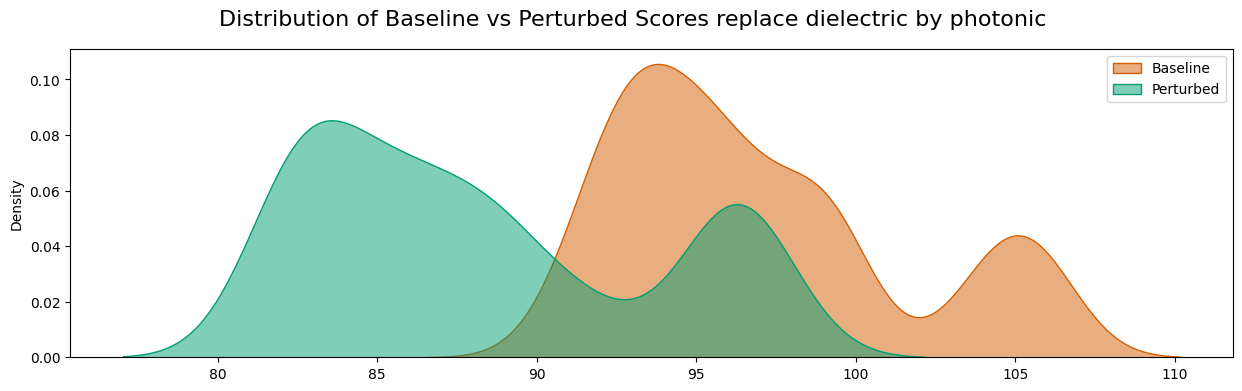

In [9]:
# Affichage des performances calculées
plot_scores(baseline_perf, perturbed_perf, pert_name)

On cherche à obtenir des profils de densité différents pour les données de base et les données perturbées. C'est cette variation qu'on va essayer d'attribuer aux composants du modèle.